In [1]:

import requests
import pandas as pd

actual_url = "https://data.elexon.co.uk/bmrs/api/v1/datasets/FUELHH/stream"

params = {
    "settlementDateFrom": "2026-01-01",
    "settlementDateTo": "2026-01-31",
    "fuelType": "WIND"
}

response = requests.get(actual_url, params=params, timeout=60)

print("Status code:", response.status_code)
print("Response preview:")
print(response.text[:1000])


Status code: 200
Response preview:
[{"dataset":"FUELHH","publishTime":"2026-02-01T00:00:00Z","startTime":"2026-01-31T23:30:00Z","settlementDate":"2026-01-31","settlementPeriod":48,"fuelType":"WIND","generation":8849},{"dataset":"FUELHH","publishTime":"2026-01-31T23:30:00Z","startTime":"2026-01-31T23:00:00Z","settlementDate":"2026-01-31","settlementPeriod":47,"fuelType":"WIND","generation":9130},{"dataset":"FUELHH","publishTime":"2026-01-31T23:00:00Z","startTime":"2026-01-31T22:30:00Z","settlementDate":"2026-01-31","settlementPeriod":46,"fuelType":"WIND","generation":9320},{"dataset":"FUELHH","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-31T22:00:00Z","settlementDate":"2026-01-31","settlementPeriod":45,"fuelType":"WIND","generation":9475},{"dataset":"FUELHH","publishTime":"2026-01-31T22:00:00Z","startTime":"2026-01-31T21:30:00Z","settlementDate":"2026-01-31","settlementPeriod":44,"fuelType":"WIND","generation":9315},{"dataset":"FUELHH","publishTime":"2026-01-31T21:30:00Z","s

In [2]:

actual_data = response.json()

actual_df = pd.DataFrame(actual_data)

print("Total records:", len(actual_df))
print("\nColumns:")
print(actual_df.columns.tolist())

print("\nFirst 5 records:")
display(actual_df.head())

print("\nLast 5 records:")
display(actual_df.tail())

print("\nFuel types:")
print(actual_df["fuelType"].value_counts())

print("\nDate range:")
print("Earliest:", actual_df["startTime"].min())
print("Latest:", actual_df["startTime"].max())


Total records: 1488

Columns:
['dataset', 'publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'fuelType', 'generation']

First 5 records:


,dataset,publishTime,startTime,settlementDate,settlementPeriod,fuelType,generation
0,FUELHH,2026-02-01T00:00:00Z,2026-01-31T23:30:00Z,2026-01-31,48,WIND,8849
1,FUELHH,2026-01-31T23:30:00Z,2026-01-31T23:00:00Z,2026-01-31,47,WIND,9130
2,FUELHH,2026-01-31T23:00:00Z,2026-01-31T22:30:00Z,2026-01-31,46,WIND,9320
3,FUELHH,2026-01-31T22:30:00Z,2026-01-31T22:00:00Z,2026-01-31,45,WIND,9475
4,FUELHH,2026-01-31T22:00:00Z,2026-01-31T21:30:00Z,2026-01-31,44,WIND,9315



Last 5 records:


,dataset,publishTime,startTime,settlementDate,settlementPeriod,fuelType,generation
1483,FUELHH,2026-01-01T02:30:00Z,2026-01-01T02:00:00Z,2026-01-01,5,WIND,14185
1484,FUELHH,2026-01-01T02:00:00Z,2026-01-01T01:30:00Z,2026-01-01,4,WIND,14077
1485,FUELHH,2026-01-01T01:30:00Z,2026-01-01T01:00:00Z,2026-01-01,3,WIND,14036
1486,FUELHH,2026-01-01T01:00:00Z,2026-01-01T00:30:00Z,2026-01-01,2,WIND,13873
1487,FUELHH,2026-01-01T00:30:00Z,2026-01-01T00:00:00Z,2026-01-01,1,WIND,13756



Fuel types:
fuelType
WIND    1488
Name: count, dtype: int64

Date range:
Earliest: 2026-01-01T00:00:00Z
Latest: 2026-01-31T23:30:00Z


In [3]:

forecast_url = "https://data.elexon.co.uk/bmrs/api/v1/datasets/WINDFOR/stream"

forecast_params = {
    "publishDateTimeFrom": "2025-12-31T00:00:00Z",
    "publishDateTimeTo": "2026-02-01T00:00:00Z"
}

forecast_response = requests.get(
    forecast_url,
    params=forecast_params,
    timeout=60
)

print("Status code:", forecast_response.status_code)
print("Response preview:")
print(forecast_response.text[:1500])


Status code: 200
Response preview:
[{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-30T21:00:00Z","generation":17683},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-30T22:00:00Z","generation":17313},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-30T23:00:00Z","generation":17030},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-31T00:00:00Z","generation":16403},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-31T01:00:00Z","generation":15966},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-31T02:00:00Z","generation":15502},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-31T03:00:00Z","generation":14800},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","startTime":"2026-01-31T04:00:00Z","generation":13755},{"dataset":"WINDFOR","publishTime":"2026-01-31T22:30:00Z","s

In [4]:

forecast_data = forecast_response.json()
forecast_df = pd.DataFrame(forecast_data)

print("Total forecast records:", len(forecast_df))
print("\nColumns:")
print(forecast_df.columns.tolist())

print("\nFirst 5 records:")
display(forecast_df.head())

print("\nLast 5 records:")
display(forecast_df.tail())

print("\nPublication time range:")
print(forecast_df["publishTime"].min())
print(forecast_df["publishTime"].max())

print("\nForecast target time range:")
print(forecast_df["startTime"].min())
print(forecast_df["startTime"].max())


Total forecast records: 18688

Columns:
['dataset', 'publishTime', 'startTime', 'generation']

First 5 records:


,dataset,publishTime,startTime,generation
0,WINDFOR,2026-01-31T22:30:00Z,2026-01-30T21:00:00Z,17683
1,WINDFOR,2026-01-31T22:30:00Z,2026-01-30T22:00:00Z,17313
2,WINDFOR,2026-01-31T22:30:00Z,2026-01-30T23:00:00Z,17030
3,WINDFOR,2026-01-31T22:30:00Z,2026-01-31T00:00:00Z,16403
4,WINDFOR,2026-01-31T22:30:00Z,2026-01-31T01:00:00Z,15966



Last 5 records:


,dataset,publishTime,startTime,generation
18683,WINDFOR,2025-12-31T02:30:00Z,2026-01-02T17:00:00Z,17884
18684,WINDFOR,2025-12-31T02:30:00Z,2026-01-02T18:00:00Z,18079
18685,WINDFOR,2025-12-31T02:30:00Z,2026-01-02T19:00:00Z,18123
18686,WINDFOR,2025-12-31T02:30:00Z,2026-01-02T20:00:00Z,18089
18687,WINDFOR,2025-12-31T02:30:00Z,2026-01-02T21:00:00Z,17949



Publication time range:
2025-12-31T02:30:00Z
2026-01-31T22:30:00Z

Forecast target time range:
2025-12-30T21:00:00Z
2026-02-02T21:00:00Z


In [5]:

# Convert timestamps into proper datetime values
actual_df["startTime"] = pd.to_datetime(actual_df["startTime"], utc=True)

forecast_df["startTime"] = pd.to_datetime(
    forecast_df["startTime"], utc=True
)
forecast_df["publishTime"] = pd.to_datetime(
    forecast_df["publishTime"], utc=True
)

# Keep forecasts whose target time falls in January 2026
jan_forecasts = forecast_df[
    (forecast_df["startTime"] >= "2026-01-01T00:00:00Z") &
    (forecast_df["startTime"] < "2026-02-01T00:00:00Z")
].copy()

print("Actual records:", len(actual_df))
print("Forecast records targeting January:", len(jan_forecasts))

print("\nUnique forecast target intervals:")
print(jan_forecasts["startTime"].nunique())

print("\nUnique publication times:")
print(jan_forecasts["publishTime"].nunique())

print("\nForecasts for one target time:")
sample_time = jan_forecasts["startTime"].iloc[0]
display(
    jan_forecasts[
        jan_forecasts["startTime"] == sample_time
    ].sort_values("publishTime")
)


Actual records: 1488
Forecast records targeting January: 17904

Unique forecast target intervals:
744

Unique publication times:
256

Forecasts for one target time:


,dataset,publishTime,startTime,generation
2335,WINDFOR,2026-01-28 02:30:00+00:00,2026-01-30 21:00:00+00:00,15457
2262,WINDFOR,2026-01-28 04:30:00+00:00,2026-01-30 21:00:00+00:00,15557
2189,WINDFOR,2026-01-28 07:30:00+00:00,2026-01-30 21:00:00+00:00,16895
2116,WINDFOR,2026-01-28 09:30:00+00:00,2026-01-30 21:00:00+00:00,17087
2043,WINDFOR,2026-01-28 11:30:00+00:00,2026-01-30 21:00:00+00:00,16925
1970,WINDFOR,2026-01-28 15:30:00+00:00,2026-01-30 21:00:00+00:00,16789
1897,WINDFOR,2026-01-28 18:30:00+00:00,2026-01-30 21:00:00+00:00,16886
1824,WINDFOR,2026-01-28 22:30:00+00:00,2026-01-30 21:00:00+00:00,17609
1727,WINDFOR,2026-01-29 02:30:00+00:00,2026-01-30 21:00:00+00:00,17212
1654,WINDFOR,2026-01-29 04:30:00+00:00,2026-01-30 21:00:00+00:00,16848


In [6]:
# Calculate how many hours before or after the target time
# each forecast was published.

jan_forecasts["lead_hours"] = (
    jan_forecasts["startTime"] - jan_forecasts["publishTime"]
).dt.total_seconds() / 3600

print("Forecast lead time (hours):")
display(jan_forecasts["lead_hours"].describe())

print("\nForecasts published after their target time:")
print((jan_forecasts["lead_hours"] < 0).sum())

print("\nSample forecasts for one target time:")
display(
    jan_forecasts[
        jan_forecasts["startTime"] == sample_time
    ][["publishTime", "startTime", "lead_hours", "generation"]]
    .sort_values("publishTime")
)

Forecast lead time (hours):


,lead_hours
count,17904.000000
mean,21.292509
std,21.966255
min,-25.500000
25%,3.500000
50%,21.500000
75%,39.500000
max,66.500000



Forecasts published after their target time:
3697

Sample forecasts for one target time:


,publishTime,startTime,lead_hours,generation
2335,2026-01-28 02:30:00+00:00,2026-01-30 21:00:00+00:00,66.5,15457
2262,2026-01-28 04:30:00+00:00,2026-01-30 21:00:00+00:00,64.5,15557
2189,2026-01-28 07:30:00+00:00,2026-01-30 21:00:00+00:00,61.5,16895
2116,2026-01-28 09:30:00+00:00,2026-01-30 21:00:00+00:00,59.5,17087
2043,2026-01-28 11:30:00+00:00,2026-01-30 21:00:00+00:00,57.5,16925
1970,2026-01-28 15:30:00+00:00,2026-01-30 21:00:00+00:00,53.5,16789
1897,2026-01-28 18:30:00+00:00,2026-01-30 21:00:00+00:00,50.5,16886
1824,2026-01-28 22:30:00+00:00,2026-01-30 21:00:00+00:00,46.5,17609
1727,2026-01-29 02:30:00+00:00,2026-01-30 21:00:00+00:00,42.5,17212
1654,2026-01-29 04:30:00+00:00,2026-01-30 21:00:00+00:00,40.5,16848


In [7]:
# Step 2: Select the latest forecast available by noon
# on the day before each target date.

# Remove forecasts that target times outside January (already done).
# Create the decision cutoff for each target time.
jan_forecasts["decision_cutoff"] = (
    jan_forecasts["startTime"].dt.floor("D")
    - pd.Timedelta(days=1)
    + pd.Timedelta(hours=12)
)

# Keep only forecasts that were published by the decision cutoff.
eligible_forecasts = jan_forecasts[
    jan_forecasts["publishTime"]
    <= jan_forecasts["decision_cutoff"]
].copy()

# For each target hour, select the most recently published eligible forecast.
selected_forecasts = (
    eligible_forecasts
    .sort_values("publishTime")
    .drop_duplicates(subset=["startTime"], keep="last")
    .copy()
)

print("Forecast records targeting January:", len(jan_forecasts))
print("Forecasts eligible by the cutoff:", len(eligible_forecasts))
print("Unique target hours with a selected forecast:", len(selected_forecasts))
print("Target hours in January:", 31 * 24)
print(
    "Target hours without an eligible forecast:",
    31 * 24 - len(selected_forecasts)
)

print("\nSelected forecast examples:")
display(
    selected_forecasts[
        ["publishTime", "decision_cutoff", "startTime", "generation"]
    ].sort_values("startTime").head(10)
)


Forecast records targeting January: 17904
Forecasts eligible by the cutoff: 8976
Unique target hours with a selected forecast: 744
Target hours in January: 744
Target hours without an eligible forecast: 0

Selected forecast examples:


,publishTime,decision_cutoff,startTime,generation
18350,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 00:00:00+00:00,19563
18351,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 01:00:00+00:00,19736
18352,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 02:00:00+00:00,19695
18353,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 03:00:00+00:00,19451
18354,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 04:00:00+00:00,19156
18355,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 05:00:00+00:00,19280
18356,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 06:00:00+00:00,19413
18357,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 07:00:00+00:00,19438
18358,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 08:00:00+00:00,19446
18359,2025-12-31 11:30:00+00:00,2025-12-31 12:00:00+00:00,2026-01-01 09:00:00+00:00,19381


In [8]:
# Step 3A: Convert actual data from half-hourly to hourly averages

actual_hourly = actual_df.copy()

# Put each half-hourly reading into its corresponding hour
actual_hourly["hour"] = actual_hourly["startTime"].dt.floor("h")

# Average the two half-hourly readings within each hour
actual_hourly = (
    actual_hourly.groupby("hour", as_index=False)["generation"]
    .mean()
    .rename(columns={
        "hour": "target_time",
        "generation": "actual_mw"
    })
)

# Step 3B: Prepare the selected forecast data
forecast_hourly = (
    selected_forecasts[["startTime", "generation"]]
    .rename(columns={
        "startTime": "target_time",
        "generation": "forecast_mw"
    })
    .copy()
)

# Step 3C: Match actual and forecast values by target hour
comparison_df = pd.merge(
    actual_hourly,
    forecast_hourly,
    on="target_time",
    how="inner",
    validate="one_to_one"
)

comparison_df = comparison_df.sort_values("target_time").reset_index(drop=True)

# Check the results
print("Hourly actual records:", len(actual_hourly))
print("Selected forecast records:", len(forecast_hourly))
print("Matched comparison records:", len(comparison_df))

print("\nMissing values:")
print(comparison_df[["actual_mw", "forecast_mw"]].isna().sum())

print("\nFirst 10 matched records:")
display(comparison_df.head(10))

print("\nLast matched target time:")
print(comparison_df["target_time"].max())

Hourly actual records: 744
Selected forecast records: 744
Matched comparison records: 744

Missing values:
actual_mw      0
forecast_mw    0
dtype: int64

First 10 matched records:


,target_time,actual_mw,forecast_mw
0,2026-01-01 00:00:00+00:00,13814.5,19563
1,2026-01-01 01:00:00+00:00,14056.5,19736
2,2026-01-01 02:00:00+00:00,14380.0,19695
3,2026-01-01 03:00:00+00:00,15103.0,19451
4,2026-01-01 04:00:00+00:00,15349.5,19156
5,2026-01-01 05:00:00+00:00,15402.5,19280
6,2026-01-01 06:00:00+00:00,15404.0,19413
7,2026-01-01 07:00:00+00:00,15350.5,19438
8,2026-01-01 08:00:00+00:00,15598.5,19446
9,2026-01-01 09:00:00+00:00,15534.5,19381



Last matched target time:
2026-01-31 23:00:00+00:00


In [9]:
import numpy as np

# Calculate errors for every hour
comparison_df["error_mw"] = (
    comparison_df["forecast_mw"] - comparison_df["actual_mw"]
)

comparison_df["absolute_error_mw"] = comparison_df["error_mw"].abs()

comparison_df["squared_error"] = comparison_df["error_mw"] ** 2

# Calculate accuracy metrics
mae = comparison_df["absolute_error_mw"].mean()

rmse = np.sqrt(comparison_df["squared_error"].mean())

bias = comparison_df["error_mw"].mean()

# MAPE is calculated only where actual generation is nonzero
nonzero_actual = comparison_df["actual_mw"] != 0

mape = (
    comparison_df.loc[nonzero_actual, "absolute_error_mw"]
    / comparison_df.loc[nonzero_actual, "actual_mw"].abs()
).mean() * 100

overforecast_pct = (
    comparison_df["error_mw"] > 0
).mean() * 100

underforecast_pct = (
    comparison_df["error_mw"] < 0
).mean() * 100

print("JANUARY 2026 — FORECAST ACCURACY")
print("-" * 40)
print(f"Matched hours:       {len(comparison_df)}")
print(f"MAE:                 {mae:,.2f} MW")
print(f"RMSE:                {rmse:,.2f} MW")
print(f"Bias:                {bias:,.2f} MW")
print(f"MAPE:                {mape:.2f}%")
print(f"Hours overforecast:  {overforecast_pct:.2f}%")
print(f"Hours underforecast: {underforecast_pct:.2f}%")

print("\n10 hours with the largest absolute errors:")
display(
    comparison_df.nlargest(10, "absolute_error_mw")[
        [
            "target_time",
            "actual_mw",
            "forecast_mw",
            "error_mw",
            "absolute_error_mw"
        ]
    ]
)

JANUARY 2026 — FORECAST ACCURACY
----------------------------------------
Matched hours:       744
MAE:                 2,017.92 MW
RMSE:                2,477.04 MW
Bias:                1,806.23 MW
MAPE:                19.68%
Hours overforecast:  85.48%
Hours underforecast: 14.52%

10 hours with the largest absolute errors:


,target_time,actual_mw,forecast_mw,error_mw,absolute_error_mw
265,2026-01-12 01:00:00+00:00,14072.0,20933,6861.0,6861.0
266,2026-01-12 02:00:00+00:00,14120.5,20891,6770.5,6770.5
264,2026-01-12 00:00:00+00:00,14032.0,20793,6761.0,6761.0
269,2026-01-12 05:00:00+00:00,14022.0,20738,6716.0,6716.0
267,2026-01-12 03:00:00+00:00,14163.0,20793,6630.0,6630.0
270,2026-01-12 06:00:00+00:00,14038.5,20657,6618.5,6618.5
268,2026-01-12 04:00:00+00:00,14224.5,20738,6513.5,6513.5
263,2026-01-11 23:00:00+00:00,14120.0,20300,6180.0,6180.0
647,2026-01-27 23:00:00+00:00,11472.0,17628,6156.0,6156.0
245,2026-01-11 05:00:00+00:00,11641.5,17776,6134.5,6134.5


Number of days: 31

First 5 daily summaries:


,date,actual_avg_mw,forecast_avg_mw,daily_mae_mw,daily_bias_mw
0,2026-01-01,15371.958333,19605.541667,4233.583333,4233.583333
1,2026-01-02,15169.083333,18460.916667,3291.833333,3291.833333
2,2026-01-03,15251.208333,17632.125000,2380.916667,2380.916667
3,2026-01-04,13343.166667,14289.208333,968.583333,946.041667
4,2026-01-05,9439.437500,9657.958333,860.854167,218.520833



10 days with the highest average absolute error:


,date,actual_avg_mw,forecast_avg_mw,daily_mae_mw,daily_bias_mw
10,2026-01-11,13557.354167,18502.208333,4944.854167,4944.854167
11,2026-01-12,14452.208333,19141.000000,4688.791667,4688.791667
0,2026-01-01,15371.958333,19605.541667,4233.583333,4233.583333
20,2026-01-21,15731.687500,19610.625000,3878.937500,3878.937500
26,2026-01-27,16408.520833,19946.166667,3537.645833,3537.645833
1,2026-01-02,15169.083333,18460.916667,3291.833333,3291.833333
27,2026-01-28,5759.791667,8751.250000,2991.458333,2991.458333
21,2026-01-22,16188.625000,18930.875000,2742.250000,2742.250000
2,2026-01-03,15251.208333,17632.125000,2380.916667,2380.916667
30,2026-01-31,10423.166667,12670.833333,2247.666667,2247.666667


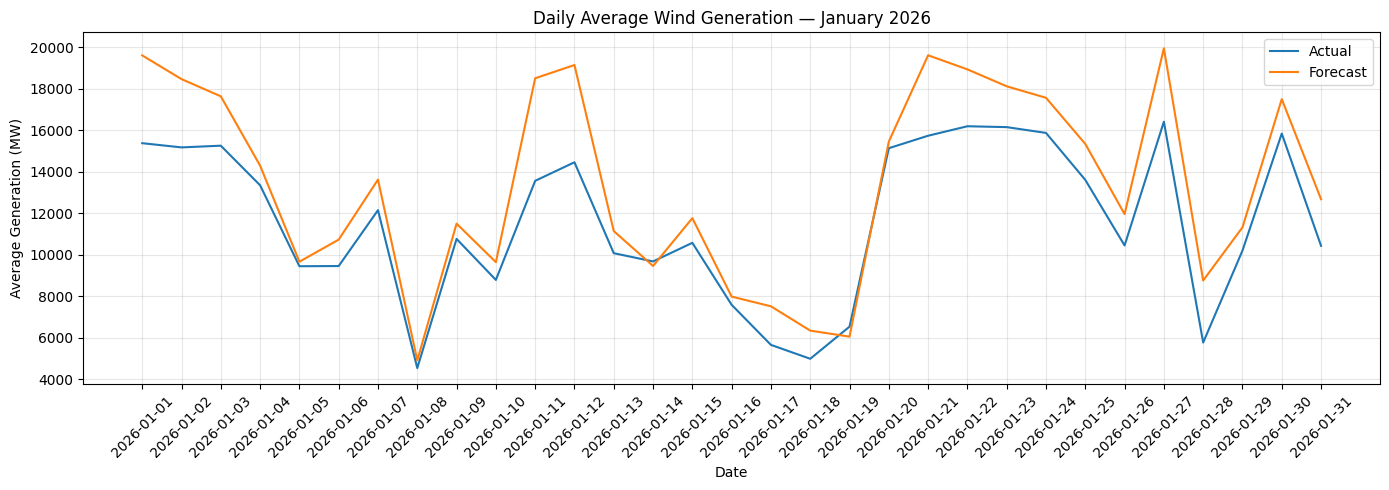

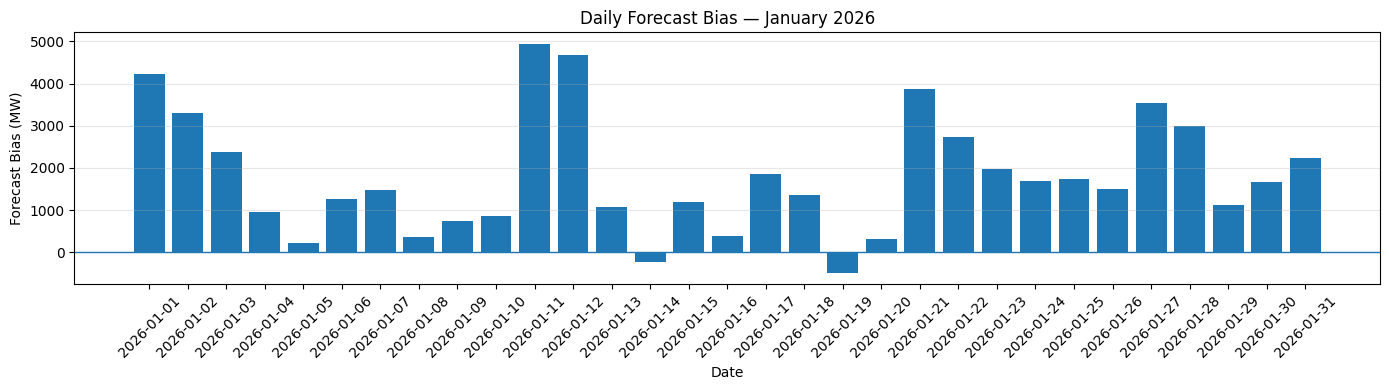

In [10]:
import matplotlib.pyplot as plt

# Group the hourly comparison into daily summaries
comparison_df["date"] = comparison_df["target_time"].dt.floor("D")

daily_summary = (
    comparison_df.groupby("date")
    .agg(
        actual_avg_mw=("actual_mw", "mean"),
        forecast_avg_mw=("forecast_mw", "mean"),
        daily_mae_mw=("absolute_error_mw", "mean"),
        daily_bias_mw=("error_mw", "mean")
    )
    .reset_index()
)

daily_summary["date"] = daily_summary["date"].dt.strftime("%Y-%m-%d")

print("Number of days:", len(daily_summary))
print("\nFirst 5 daily summaries:")
display(daily_summary.head())

print("\n10 days with the highest average absolute error:")
display(
    daily_summary.nlargest(10, "daily_mae_mw")
)

# Plot daily average actual vs forecast generation
plt.figure(figsize=(14, 5))
plt.plot(
    daily_summary["date"],
    daily_summary["actual_avg_mw"],
    label="Actual",
)
plt.plot(
    daily_summary["date"],
    daily_summary["forecast_avg_mw"],
    label="Forecast",
)

plt.title("Daily Average Wind Generation — January 2026")
plt.xlabel("Date")
plt.ylabel("Average Generation (MW)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot daily forecast error
plt.figure(figsize=(14, 4))
plt.bar(daily_summary["date"], daily_summary["daily_bias_mw"])
plt.axhline(0, linewidth=1)
plt.title("Daily Forecast Bias — January 2026")
plt.xlabel("Date")
plt.ylabel("Forecast Bias (MW)")
plt.xticks(rotation=45)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
import json

# 1. Export hourly comparison data
hourly_export = comparison_df[
    [
        "target_time",
        "actual_mw",
        "forecast_mw",
        "error_mw",
        "absolute_error_mw"
    ]
].copy()

hourly_export["target_time"] = (
    hourly_export["target_time"].astype(str)
)

hourly_export.to_csv("hourly_comparison.csv", index=False)


# 2. Export daily summary data
daily_export = daily_summary.copy()
daily_export.to_csv("daily_summary.csv", index=False)


# 3. Create dashboard summary metrics
dashboard_metrics = {
    "period": "January 2026",
    "matched_hours": int(len(comparison_df)),
    "days_analysed": int(len(daily_summary)),
    "mae_mw": round(float(mae), 2),
    "rmse_mw": round(float(rmse), 2),
    "bias_mw": round(float(bias), 2),
    "mape_percent": round(float(mape), 2),
    "overforecast_percent": round(float(overforecast_pct), 2),
    "underforecast_percent": round(float(underforecast_pct), 2),
    "decision_cutoff": "12:00 UTC on the day before each target date"
}

with open("dashboard_metrics.json", "w") as f:
    json.dump(dashboard_metrics, f, indent=2)


# 4. Verify the exported files
print("Files created successfully:")
print("- hourly_comparison.csv")
print("- daily_summary.csv")
print("- dashboard_metrics.json")

print("\nMetrics JSON preview:")
print(json.dumps(dashboard_metrics, indent=2))

Files created successfully:
- hourly_comparison.csv
- daily_summary.csv
- dashboard_metrics.json

Metrics JSON preview:
{
  "period": "January 2026",
  "matched_hours": 744,
  "days_analysed": 31,
  "mae_mw": 2017.92,
  "rmse_mw": 2477.04,
  "bias_mw": 1806.23,
  "mape_percent": 19.68,
  "overforecast_percent": 85.48,
  "underforecast_percent": 14.52,
  "decision_cutoff": "12:00 UTC on the day before each target date"
}


In [12]:
from google.colab import files

files.download("hourly_comparison.csv")
files.download("daily_summary.csv")
files.download("dashboard_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>